# G93 Integrative Project - KPIs and Statistical Analysis

In this notebook, we will analyze everything related to the "Stations_Data.csv" file. The .csv file contains these variables:

- **Station**: {Berlin, Hamburg, Hannover, Frankfurt, Stuttgart}
- **Year**: (2015–2024)
- **Month**: (1–12)
- **Arrival of trains**: number
- **Iron**: tons
- **Coal**: tons
- **Steel**: tons
- **Vegetables**: tons
- **Cereals**: tons
- **Wool**: tons
- **Coffee**: tons
- **Cattle**: tons
- **Passengers**: number
- **Mail**: tons
- **Revenues**: Millions (€)
- **Expenses**: Millions (€)

The analysis will be divided into 4 user storys (US) (for Sprint2), which are the following:

1. **US15 - As a Player, I want to perform a statistical analysis of the aver age annual profit of a user-specified railway station.**
2. **US16 - As a Player, I want to perform a comparative analysis of passenger arrivals across all stations.**
3. **US17 - As a Player, I want to perform an analysis of the cargo arriving at each station using all recorded data.**
4. **US18 - As a Player, I want to perform the analysis of train distribution, passengers, and mail across different stations**

In Sprint 3, the following were added:
1. **US29 - As a Product Owner, I want to run tests for variable-sized inputs to observe graphically the asymptotic behavior of the execution time of the US13 and US14 procedures (excluding graphic visualization)**
2. **US30 - As a Product Owner, I want to obtain the best-fitting curve for the previous sample, and see it graphically.**
3. **US31 -  As a Player, using the same data file as in the previous Sprint (Sprint 2), I want to perform a statistical analysis to determine which type of cargo contributes most significantly to the revenue of a given station, in a specific year, both defined by the user**

In each section (dedicated to one US), there will be a theoretical explanation about the statistical concepts that will be used, alongside the Python code to obtain the results.

## **US15: Statistical Analysis of the average annual profit of a user-specified railway station**

### **User Story Details**

As a Player, I want to perform a statistical analysis of the average annual profit of a user-specified railway station. In order to achieve this, a table with key descriptive measures: mean, standard deviation, median, and mode will be generated. Additionally, the analysis aims to identify outlier profits as well as to determine the most and least profitable years.

### **Theoretical Explanation**

#### What is a mean?

It's a quantity representing the "center" of a collection of numbers and is intermediate to the extreme values of the set of numbers.

$$\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$$

#### What is a standard deviation?

It's a measure of the amount of variation of the values of a variable about its mean.

**Sample Standard Deviation Formula:**
$$s = \sqrt{\frac{1}{n-1} \sum_{i=1}^{n} (x_i - \bar{x})^2}$$

**Population Standard Deviation Formula:**
$$\sigma = \sqrt{\frac{1}{N} \sum_{i=1}^{N} (x_i - \mu)^2}$$

#### What is a median?

It's a set of numbers is the value separating the higher half from the lower half of a data sample, a population, or a probability distribution.

**For odd number of values:**
$$\text{Median} = x_{\frac{n+1}{2}}$$

**For even number of values:**
$$\text{Median} = \frac{x_{\frac{n}{2}} + x_{\frac{n}{2}+1}}{2}$$

#### What is a mode?

It's a way of expressing, in a (usually) single number, important information about a random variable or a population.

$$\text{Mode} = \text{value with highest frequency}$$

#### What is an outlier?

It's a data point that differs significantly from other observations.

$$\text{IQR} = Q_3 - Q_1$$
$$\text{Lower Bound} = Q_1 - 1.5 \times \text{IQR}$$
$$\text{Upper Bound} = Q_3 + 1.5 \times \text{IQR}$$

### **Code for US15**

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Stations_Data.csv', sep=';')

num_cols = [
    'Revenues', 'Expenses'
]
for col in num_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '.', regex=False),
        errors='coerce'
    )

df['Profit'] = df['Revenues'] - df['Expenses']
annual_profit = (
    df
    .groupby(['Station', 'Year'], as_index=False)['Profit']
    .sum()
)

print("Available stations:")
available_stations = sorted(annual_profit['Station'].unique())
for i, station in enumerate(available_stations, 1):
    print(f"{i}. {station}")

station = None
while station is None:
    user_input = input("\nInsert the station's name: ").strip()
    if not user_input:
        print("Error: Please enter a station name. It cannot be empty.")
        continue
    matching_stations = [s for s in available_stations if s.lower() == user_input.lower()]
    
    if matching_stations:
        station = matching_stations[0]  
    else:
        print(f"Error: Station '{user_input}' not found.")
        print("Please choose from the available stations listed above.")
        similar_stations = [s for s in available_stations if user_input.lower() in s.lower()]
        if similar_stations:
            print(f"Did you mean one of these? {', '.join(similar_stations)}")

station_data = annual_profit[annual_profit['Station'] == station]

profits = station_data['Profit']
years = station_data['Year']

mean = profits.mean()
std = profits.std()
median = profits.median()
mode = profits.mode().iloc[0] if not profits.mode().empty else None

print(f"\nDescriptive measures for station: '{station}':")
print(f"Mean: {mean:.2f}")
print(f"Standard deviation: {std:.2f}")
print(f"Median: {median:.2f}")
print(f"Mode: {mode:.2f}")

Q1 = profits.quantile(0.25)
Q3 = profits.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = station_data[
    (station_data['Profit'] < lower) |
    (station_data['Profit'] > upper)
]

print(f"\nFound outliers ({len(outliers)}):")
if not outliers.empty:
    print(outliers[['Year', 'Profit']].to_string(index=False))

    max_row = station_data.loc[profits.idxmax()]
    min_row = station_data.loc[profits.idxmin()]
    print(f"\nMost profitable year: {int(max_row['Year'])} -> {max_row['Profit']:.2f}")
    print(f"Least profitable year: {int(min_row['Year'])} -> {min_row['Profit']:.2f}")
else:
    print("No outlier found.")

Available stations:
1. Berlin
2. Frankfurt
3. Hamburg
4. Hannover
5. Stuttgart



Insert the station's name:  Berlin


Station 'Berlin' found!

Descriptive measures for station: 'Berlin':
Mean: 11566.76
Standard deviation: 12486.26
Median: 7564.43
Mode: 655.76

Found outliers (1):
 Year  Profit
 2023 39684.9

Most profitable year: 2023 -> 39684.90
Least profitable year: 2015 -> 655.76


### **Interpretation of the obtained results**

By closely examining the data table for the selected station, we can better understand how its profits have changed over the years. This includes finding which years made the most and least money, spotting trends in the station’s overall performance, and identifying any unusual values, or outliers, that don’t fit the general pattern. These outliers may point to special events or changes that affected the station’s income during certain years.

## **US16: Comparative analysis of passenger arrivals across all stations**

### **User Story Details**

As a Player, I want to perform a comparative analysis of passenger arrivals across all stations. To achieve this, a boxplot will be created for each station, displaying the number of arriving passengers using all recorded data. This visualization will facilitate the identification of trends, variations, and anomalies in passenger traffic across different stations.

### **Theoretical Explanation**

#### What is a trend? 

A trend is the slow variation over a longer period of time, generally associated with the structural causes affecting the phenomenon being measured.

**Mathematical representation of trend:**
$$T_t = f(t)$$

#### **What is a boxplot?**
A boxplot (box-and-whisker plot) is a standardized way of displaying the distribution of data based on five key summary statistics: minimum, first quartile (Q1), median (Q2), third quartile (Q3), and maximum. A boxplot can have individual values that differ too much from the other values represented by points called Outliers.
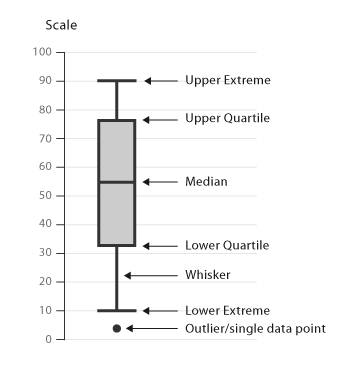

#### **What are variations?**
Variations refer to the degree of change or dispersion in passenger arrival data. They can be measured using several statistical measures:

**Variance:**
$$\sigma^2 = \frac{1}{N} \sum_{i=1}^{N} (x_i - \mu)^2$$

#### **What are anomalies?**
Anomalies are data points that deviate significantly from the expected pattern or normal behavior. In passenger arrival data, anomalies might indicate:
- Special events affecting travel patterns
- Data collection errors
- Unusual circumstances (holidays, strikes, weather events)

### **Code for US16**

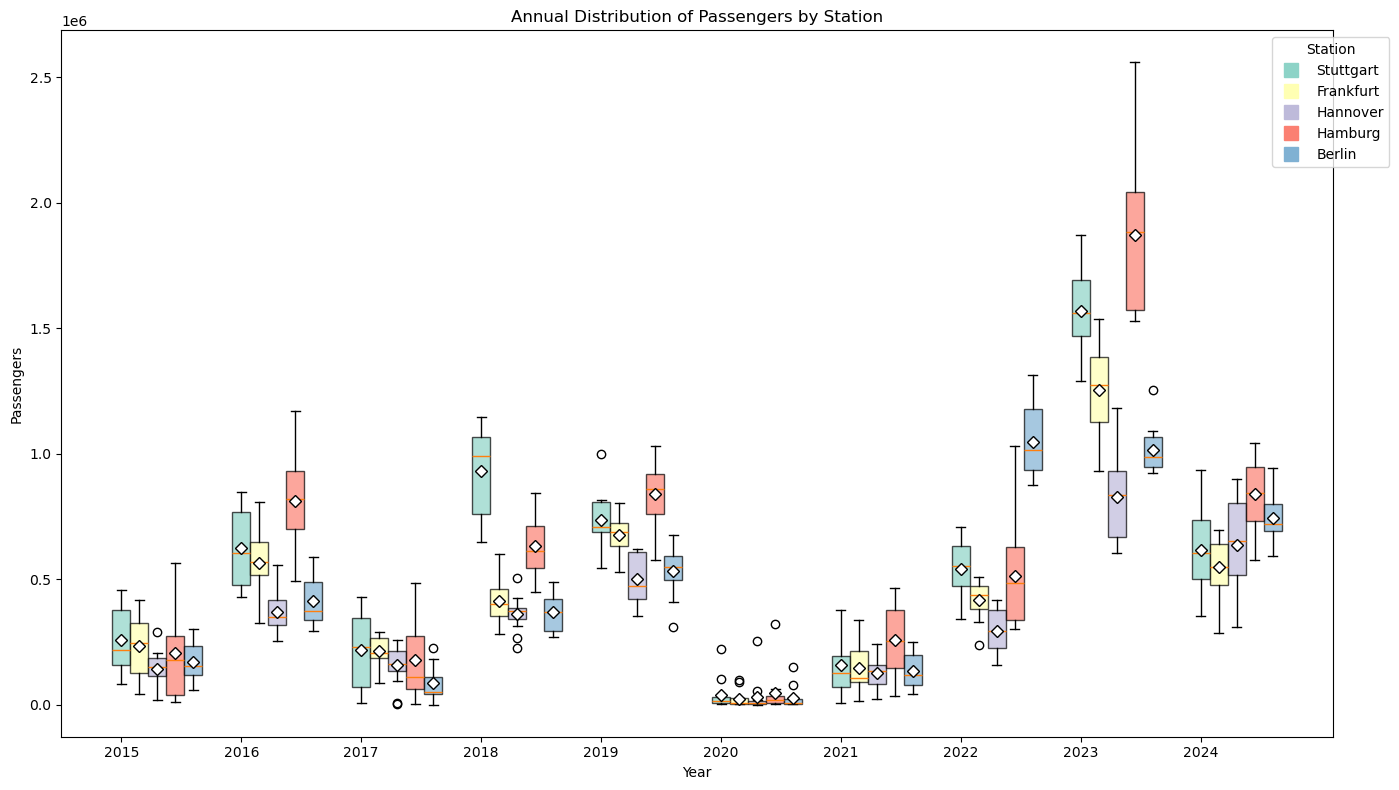

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv('Stations_Data.csv', sep=';', decimal=',')

stations = data['Station'].unique()
years = sorted(data['Year'].unique())

fig, ax = plt.subplots(figsize=(14, 8))

colors = ['#8dd3c7', '#ffffb3', '#bebada', '#fb8072', '#80b1d3']

for i, station in enumerate(stations):
    station_data = [data[(data['Year'] == year) & (data['Station'] == station)]['Passengers'] for year in years]
    box = ax.boxplot(
        station_data,
        positions=[y + i * 0.15 for y in range(len(years))],
        widths=0.15,
        patch_artist=True,
        boxprops=dict(facecolor=colors[i % len(colors)], alpha=0.7),
        meanline=False,
        showmeans=True,
        meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black')
    )

ax.set_xticks(range(len(years)))
ax.set_xticklabels(years)
ax.set_xlabel('Year')
ax.set_ylabel('Passengers')
ax.set_title('Annual Distribution of Passengers by Station')

handles = [plt.Line2D([0], [0], color=color, marker='s', linestyle='None', markersize=10) for color in colors]
ax.legend(handles, stations, title='Station', bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

### **Interpretation of the obtained results**

In this US, we can see the visual representation of yearly passenger arrivals throughout 5 stations: Stuttgart, Frankfurt, Hannover, Hamburg and Berlin, each identified by a color defined in the top right corner of the graph.

By interpreting the graph, we can see that in 2020 (start of COVID) the passenger arrivals thoughout the stations were in their minimum. During that time, trains were almost stopped, since the governments didn't want the infection to spread. We can also see that in 2021, when the Covid-19 pandemic started to calm down, the amount of passengers in stations were much higher.

Lastly, we can see that 2023 was the year with the most amount of passengers across all stations, as well as registered years, by a huge margin.

## **US17: Analysis of the cargo arriving at each station using all recorded data**

### **User Story Details**

As a Player, I want to perform an analysis of the cargo arriving at each station using all recorded data. Given the station’s name and cargo type specified by the user, a histogram will be created to visually represent the distribution of analyzed information, providing insights into cargo patterns.

### **Theoretical Explanation**

#### What does 'Binning' mean? 

- Dividing the range of cargo‐weights (or counts) into contiguous, non‐overlapping intervals (“bins”) {𝐴1,𝐴2,…,𝐴𝑘}

#### What does Histogram mean? 

- Histogram is a diagram consisting of rectangles whose area is proportional to the frequency of a variable and whose width is equal to the class interval.

#### Freedman Diaconis Rule
- A principle method that allows to choose the number of bins.
- We are able to calculate the width (w) using the following formula:
\begin{equation}
w = 2 \times \frac{\text{IQR}}{n^{1/3}}
\end{equation}

Where:
\begin{equation} {\text{IQR}} = Q_3 - Q_1 \end{equation} 
Q3 and Q1 represent the 75th and 25th percentiles respectively

- After calculating the width, we need the number (k) of bins. We can know it, using (formula only applies if IQR != 0):

\begin{equation}
k = \left\lceil \frac{\max(x) - \min(x)}{h} \right\rceil
\end{equation}

However, if  IQR = 0 , you can get the value of k using:

\begin{equation}
k \approx \sqrt{n}
\end{equation}

### **Code for US17**

Select one station from the following:
 - Berlin
 - Frankfurt
 - Hamburg
 - Hannover
 - Stuttgart


>>  Stuttgart


Select one type of cargo from the following:
 - Iron
 - Coal
 - Steel
 - Vegetables
 - Cereals
 - Wool
 - Coffee
 - Cattle


>>  Coal


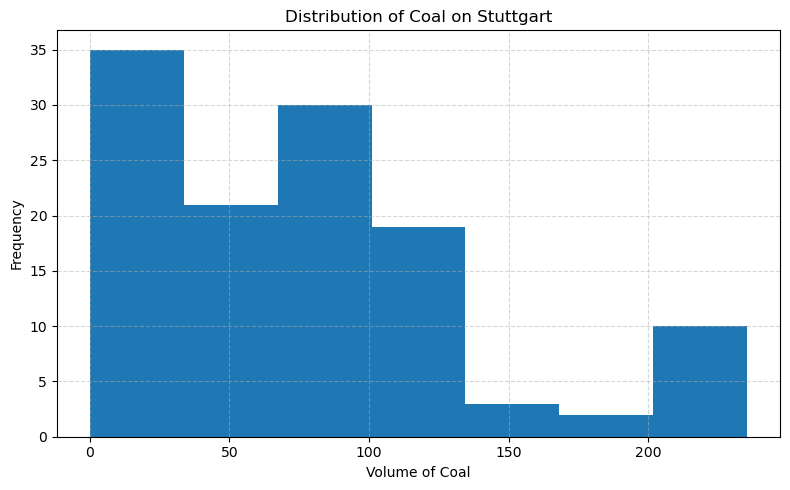

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def load_and_prepare_data(path: str):
    df = pd.read_csv(path, sep=';', decimal=',')
    non_cargo_cols = ['Station', 'Year', 'Month', 'Arrivals', 'Revenues', 'Expenses', 'Passengers', 'Mail']
    cargo_cols = [col for col in df.columns if col not in non_cargo_cols]
    for col in cargo_cols:
        if df[col].dtype == 'object':
            df[col] = df[col].str.replace(',', '.').astype(float)
    return df, cargo_cols

def choose_from_list(prompt: str, options: list[str]) -> str:
    print(prompt)
    for opt in options:
        print(" -", opt)
    choice = None
    while choice not in options:
        choice = input(">> ").strip()
        if choice not in options:
            print(f"'{choice}' não está na lista. Tenta outra vez.")
    return choice

def calc_fd_bins(data: np.ndarray) -> int:
    q75, q25 = np.percentile(data, [75, 25])
    iqr = q75 - q25
    n = len(data)
    if iqr == 0:
        return int(np.sqrt(n)) or 1
    bin_width = 2 * iqr / (n ** (1/3))
    data_range = data.max() - data.min()
    bins = int(np.ceil(data_range / bin_width))
    return bins if bins > 0 else int(np.sqrt(n)) or 1

def plot_cargo_distribution(df: pd.DataFrame, station: str, cargo: str):
    subset = df[df['Station'] == station]
    data = subset[cargo].dropna().values
    bins = calc_fd_bins(data)
    
    plt.figure(figsize=(8, 5))
    plt.hist(data, bins=bins)
    plt.xlabel(f"Volume of {cargo}")
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {cargo} on {station}")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

df, cargo_cols = load_and_prepare_data('Stations_Data.csv')

stations = sorted(df['Station'].unique())
station = choose_from_list("Select one station from the following:", stations)

cargo = choose_from_list("Select one type of cargo from the following:", cargo_cols)

plot_cargo_distribution(df, station, cargo)


### **Interpretation of the obtained results**

Using the histogram information, we are able to get some conclusions regarding this station and this type of cargo.
- Number of observations: By counting the frequency, we are able to determine that there are 120 observations;
- The InterQuartile Range (IQR) : 85.58;
- The Histogram Shape: When the x is between [0,100[ , the frequency is increased, even more if we compare when the volume is between [100, +∞[;

#### Combined Insight 
A large IQR combined with a right-skewed histogram means that Stuttgart’s coal shipments are both highly variable and occasionally experience substantial spikes. In practice, the planning should cover normal months but be ready for occasional big shipments, since the spikes are common when the volume of Coal that arrives is not superior than 100~150.

## **US18: Distribution Analysis of Trains, Passengers, and Mail**

### **User Story Details**

As a Player, I want to perform the analysis of train distribution, passengers, and mail across different stations. Using all recorded data, this distribution will be visually represented through three pie charts, providing a clear and comprehensive overview of how these elements are allocated among the stations.

### **Theoretical Explanation**

#### What is a Pie Chart?

A pie chart represents the relative frequency or percentage of categorical data. In our case, the categories we are interested in are the total number of train arrivals, total passenger counts, and total mail (in tons) recorded across all stations.

#### What is the Absolute Frequency?

The absolute frequency of a value  is simply the count of how many times that value (or any sort of data input) appears in a certain dataset.

#### What is the Relative Frequency?

The relative frequency of a value is the proportion of the total observations that that value (or any sort of data input) represents. It is obtained by dividing the absolute frequency by the total number of observations 𝑛. It can be calculated using:

\begin{equation}
r_i = \frac{f_i}{\sum_j f_j} \times 100\% 
\end{equation}

#### Visualization of Proportions on the Pie Chart

The full circle represents 100% of the data. Each slice of the circle is proportional to the relative frequency they represent:

\begin{equation}
\text{Angle}_i = 360^\circ \times r_i\,/100
\end{equation}

### Data and Labels

- The data should be mutually exclusive (which means that all the data on a pie chart must belong to the same category);
- To help understand the data the pie chart is representing, we shoud use labels and relative frequency display;

### **Code for US18**

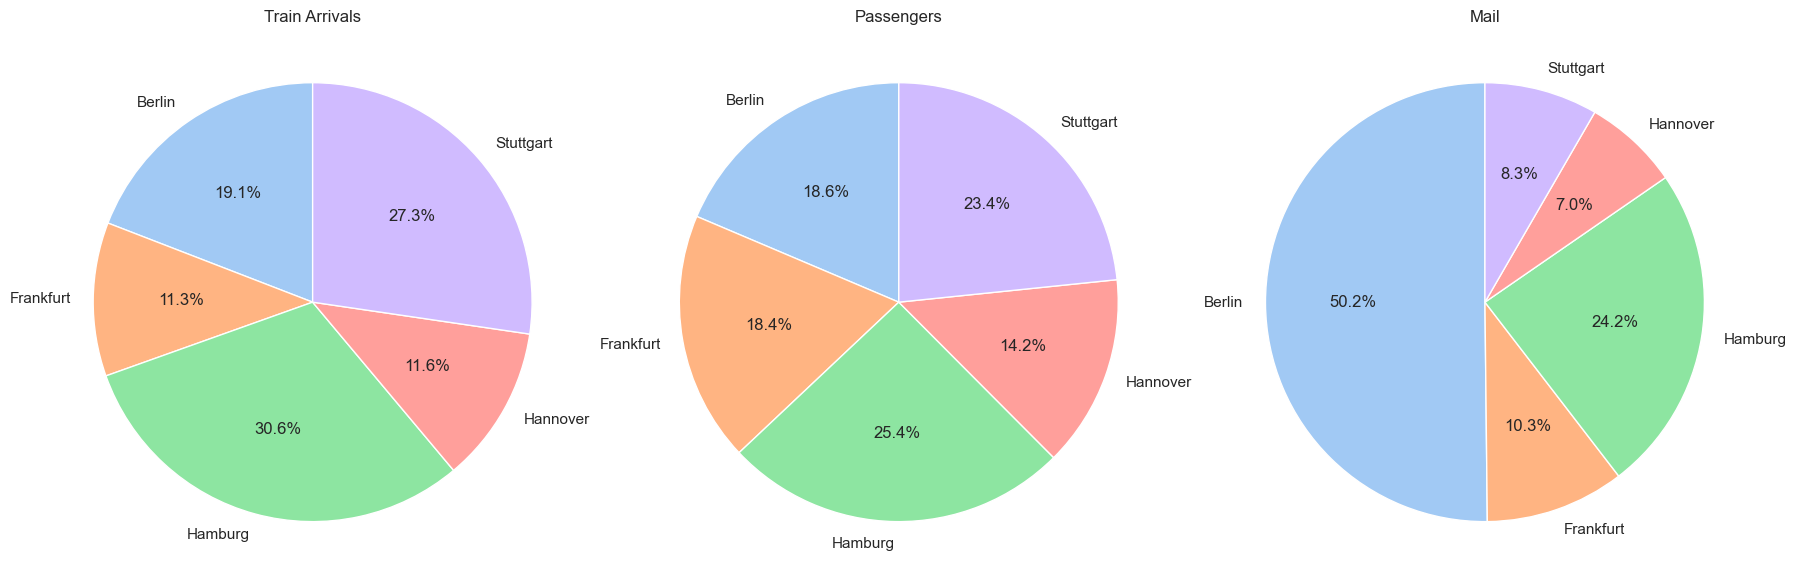

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

caminho_ficheiro = 'Stations_Data.csv'
df = pd.read_csv(caminho_ficheiro, sep=';')

# Transforming data into numbers, by replacing ',' with '.'
colunas = ['Arrivals', 'Passengers', 'Mail']
for col in colunas:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '.'),
        errors='coerce'
    )

df_agrupado = df.groupby('Station', as_index=False).agg({
    'Arrivals': 'sum',
    'Passengers': 'sum',
    'Mail': 'sum'
})

plt.figure(figsize=(18, 6))

categorias = ['Arrivals', 'Passengers', 'Mail']
titulos = ['Train Arrivals', 'Passengers', 'Mail']

for i, categoria in enumerate(categorias, 1):
    plt.subplot(1, 3, i)
    data = df_agrupado[['Station', categoria]].copy()
    
    plt.pie(
        data[categoria],
        labels=data['Station'],
        autopct='%1.1f%%',
        startangle=90,
        colors=sns.color_palette('pastel')
    )
    plt.axis('equal')
    plt.title(titulos[i - 1])

plt.tight_layout()
plt.show()


### **Interpretation of the obtained results**

Using the information presented on the Stations_Data.csv, three pie charts are created:
- Trains Arrivals;
- Passengers;
- Mail;

For each chart:
- Absolute frequencies represent the aggregated totals per station;
- Relative frequencies are represented by each slice, and using the percentages;

By analyzing each chart:
- *Train Arrivals*: Hamburg and Stuttgart represent more than half of the total Train Arrivals;
- *Passengers*: The passengers seem to be close to equally distributed;
- *Mail*: Berlin alone represents half of the mail;

Understanding these pie charts allows, for example, a certain commercial team is able to analyze what stations are more profitable for each type of cargo, allowing them to know in which station they should invest according to the type of cargo the team is responsible for

## **US31: Statistical Analysis on Cargo**

### **User Story Details**

As a Player, using the same data file as in the previous Sprint (Sprint 2), I want to perform a statistical analysis to determine which type of cargo contributes most significantly to the revenue of a given station, in a specific year, both defined by the user. The goal for the specified station/year is to identify the cargo (independent variable) that shows the highest correlation with revenue (dependent variable). Based on the selected cargo, a linear regression model should be aplied, presenting the error associated with the respective fit. Assuming the amount of cargo increased by 10% in January of the following year, estimate the expected revenue for January with a 95% confidence level.
    
### **Theoretical Explanation**

#### What is a Linear Regression?

Linear regression is a statistical method used to model and analyze the relationship between two or more variables. Linear regression seeks to fit a straight line through a cloud of data points in a way that the overall distance between the points and the line is minimized.

#### What is the Pearson Correlation?

Measures the linear association between X and Y using the following formula:

\begin{equation}
r = \frac{\sum_{i=1}^n (X_i - \bar X)\,(Y_i - \bar Y)}
         {\sqrt{\sum_{i=1}^n (X_i - \bar X)^2}\;\sqrt{\sum_{i=1}^n (Y_i - \bar Y)^2}}.
\end{equation}

The hypothesis test as this format:

\begin{equation}
H_0: \rho = 0
\quad\text{and}\quad
H_1: \rho \neq 0
\end{equation}

#### Prediction & 95 % Confidence Interval

We are able to calculate the average of the a certain cargo (x) for January of next year:

\begin{equation}
bar X_{\text{Jan}}
= \frac{1}{m}\sum_{i:\,\text{month}_i=1} X_i
\end{equation}

#### Increase of 10%

Assuming an increase of 10%, we can calculate it by using:

\begin{equation}
X^* = 1.10 \;\times\; \bar X_{\text{Jan}}
\end{equation}


### **Code for US31**

Available Stations:
1. Berlin
2. Frankfurt
3. Hamburg
4. Hannover
5. Stuttgart



Enter station name:  Frankfurt



Available years for 'Frankfurt': 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024


Enter year:  2021



Cargo with highest correlation: coal
Prediction for January 2022 (10% increase): 605.02
95% Confidence Interval: (414.72, 795.33)


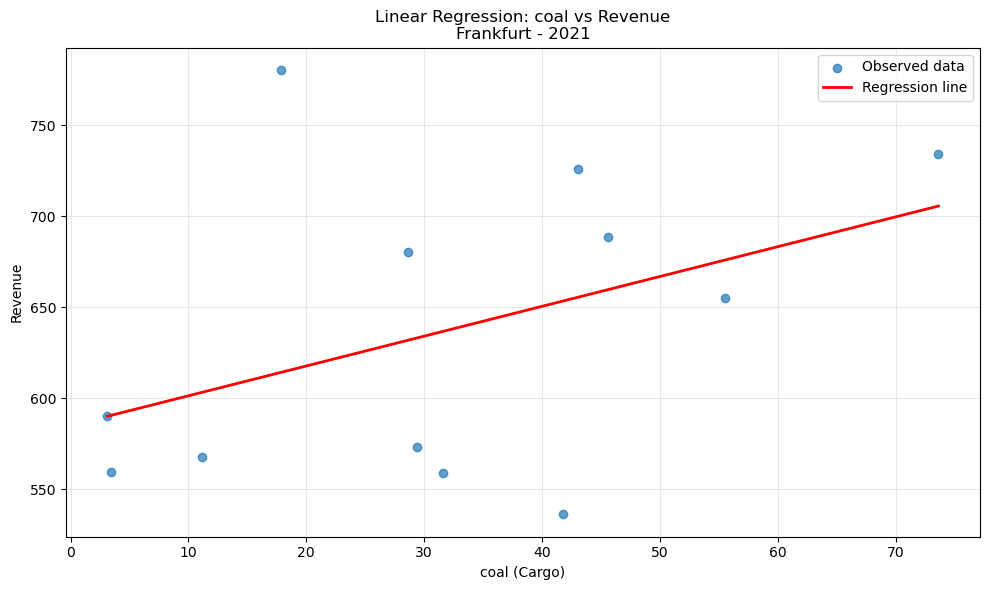

In [23]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv('Stations_Data.csv', sep=';')
df.columns = df.columns.str.strip().str.lower()
df.rename(columns={'revenues': 'revenue'}, inplace=True)

non_num = ['station', 'year', 'month']
for col in df.columns:
    if col not in non_num:
        df[col] = df[col].astype(str).str.replace(',', '.', regex=False)
        df[col] = pd.to_numeric(df[col], errors='coerce')

df['station'] = df['station'].str.strip()

print("Available Stations:")
all_stations = sorted(df['station'].unique())
for i, station_name in enumerate(all_stations, 1):
    print(f"{i}. {station_name}")

def get_valid_inputs():
    while True:
        station = input("\nEnter station name: ").strip()
        if station not in df['station'].values:
            print(f"Error: Station '{station}' not found.")
            continue
        
        available_years = sorted(df[df['station'] == station]['year'].unique())
        print(f"\nAvailable years for '{station}': {', '.join(map(str, available_years))}")
        
        try:
            year = int(input("Enter year: "))
        except ValueError:
            print("Error: Please enter a valid year.")
            continue
        
        if year not in available_years:
            print(f"Error: Year {year} not available for station '{station}'.")
            continue
        
        return station, year

station, year = get_valid_inputs()

data = df[(df['station'] == station) & (df['year'] == year)].copy()

if data.empty:
    print(f"No data found for station '{station}' in year {year}.")
else:
    exclude = ['station', 'year', 'month', 'revenue', 'expenses']
    cargo_columns = [col for col in data.columns if col not in exclude]

    correlations = {}
    for cargo in cargo_columns:
        vals = data[[cargo, 'revenue']].dropna()
        if len(vals) >= 2:
            r, _ = stats.pearsonr(vals[cargo], vals['revenue'])
            correlations[cargo] = r
    
    if not correlations:
        print("No valid cargo columns for correlation analysis.")
    else:
        best_cargo = max(correlations, key=correlations.get)
        r_best = correlations[best_cargo]

        x = data[best_cargo].values
        y = data['revenue'].values
        slope, intercept, r_value, p_value, stderr = stats.linregress(x, y)
        y_pred = intercept + slope * x

        n = len(x)
        residuals = y - y_pred
        s2 = np.sum(residuals**2) / (n - 2)
        Sxx = np.sum((x - x.mean())**2)
        t_val = stats.t.ppf(0.975, df=n - 2)

        data_jan = data[data['month'] == 1]
        if data_jan.empty:
            print(f"No January data available for year {year}.")
        else:
            jan_avg = data_jan[best_cargo].mean()
            xp = jan_avg * 1.10  
            yp = intercept + slope * xp
            interval = t_val * np.sqrt(s2 * (1 + 1/n + ((xp - x.mean())**2 / Sxx)))
            print(f"\nCargo with highest correlation: {best_cargo}")
            print(f"Prediction for January {year+1} (10% increase): {yp:.2f}")
            print(f"95% Confidence Interval: ({yp - interval:.2f}, {yp + interval:.2f})")
            
            plt.figure(figsize=(10, 6))
            sorted_idx = np.argsort(x)
            plt.scatter(x, y, alpha=0.7, label='Observed data')
            plt.plot(x[sorted_idx], y_pred[sorted_idx], 'r-', label='Regression line', linewidth=2)
            plt.xlabel(f'{best_cargo} (Cargo)')
            plt.ylabel('Revenue')
            plt.title(f'Linear Regression: {best_cargo} vs Revenue\n{station} - {year}')
            plt.legend()
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()

### **Interpretation of the obtained results**

In Frankfurt, during the year of 2021, coal is the cargo that remains on top. Using the Pearson correlation, we estimate a value of nearly 0.42, which indicates a moderate positive relationship between the coal throughput and the station income. By projecting a 10% increase on coal in January of 2022 (based on the January 2021 average), the revenue forecast seems to be around 605. The 95% confidence interval for this prediction is between [415,795]. Finally, by analyzing all the data we gathered until now, the results hint that the coal volume may lead to an increase of revenue to a certain extent, but the more data we have, the more accurate and additional predictons we are able to make. 

# Conclusion

During the development of this project, by using mathematical concepts such as Quartiles, and data representation methods, like Pie Charts, we are able to statistically analyzie everything in the "Stations_Data.csv" file.

## Contribution (in %) of each team member

| Team Member          | Contribution (%) |
|----------------------|------------------|
| Diogo Silva (1241229)      | &#x5B; 33.4  &#x5D;   |
| Gonçalo Tavares (1241234)      | &#x5B; 33.3 &#x5D;   |
| Gonçalo Pinto (1241232)      | &#x5B; 33.3 &#x5D;   |

_Total: 100 %_
